In [123]:
import os
os.chdir(r"C:\Users\jules\OneDrive - University of Delaware - o365\math637 data science\final project\Math637_Final_Project")

In [124]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np 
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error

data = pd.read_csv("data/modeling_data.csv", parse_dates=["timestamp_utc"])
data.columns


Index(['cursor', 'timestamp_utc', 'published_at_utc', 'building_id',
       'demand_kw', 'temperature_c', 'weather_observed_at_utc',
       'weather_received_at_utc', 'weather_age_seconds', 'weather_source',
       'quality', 'scorable', 'ingested_at_utc'],
      dtype='str')

In [125]:
Steps_per_hour=4
horizons_hours= [6,24]
Test_days=3
def build_training_table(building_data, horizon_steps): # horizon steps is how far ahead to predict, so 6hr or 24hr periods
    series= (building_data.set_index("timestamp_utc").sort_index()[["demand_kw", "temperature_c"]].asfreq("15min"))
    # series uses timestamp as the row label, sorting oldest to newest.
    #series consists of demand and temperature, and force each row to be 15 minutes
    features= pd.DataFrame(index=series.index)
    features["demand_now"] = series["demand_kw"]
    features["demand_1h_ago"] = series["demand_kw"].shift(4) #1 hour
    features["demand_24h_ago"] = series["demand_kw"].shift(96) #24 hours
    features["demand_7d_ago"] = series["demand_kw"].shift(672) # 1 week
    features["temp_at_origin"] = series["temperature_c"]
    features["temp_at_target"] = series["temperature_c"].shift(-horizon_steps) #for now real, later change to forecasted temp!!
    target_time = features.index + pd.Timedelta(minutes=15 * horizon_steps)
    features["target_hour_sin"] = np.sin(2*np.pi*target_time.hour /24) #you want time to be consecutive. 23:00 and 0:00 are 23 apart otherwise instead of 1 hour
    features["target_hour_cos"] = np.cos(2*np.pi*target_time.hour /24) #same as above
    features["target_weekday_sin"] = np.sin(2 * np.pi * target_time.day_of_week / 7) #want days of the week to be consecutive. saturday=6 to sunday=0 is a big difference
    features["target_weekday_cos"] = np.cos(2 * np.pi * target_time.day_of_week / 7)
    features["Demand_at_target_yesterday"] = series["demand_kw"].shift(96 - horizon_steps)
    features["actual_demand_at_target"] = series["demand_kw"].shift(-horizon_steps)
    features["is_weekend"]= (target_time.day_of_week >=5).astype(int) #is it the weekend
    features["is_between_8am_10pm"]= ((target_time.hour >=8) & (target_time.hour < 22)).astype(int)
    # EIA-inspired heating and cooling features
    features["heating_degree"] = (
        18 - features["temp_at_target"]
    ).clip(lower=0)

    features["cooling_degree"] = (
        features["temp_at_target"] - 22
    ).clip(lower=0)
    return features.dropna()


consider later adding features: is_weekend, demand_2h_ago

In [126]:
def main():
    data = pd.read_csv("data/modeling_data.csv", parse_dates=["timestamp_utc"])
    for hour in horizons_hours:
        horizon_steps = hour * Steps_per_hour
        print(f" {hour}-Hour Forecast")
        mae_score=[]
        rmse_score=[]
        for building_id, building_data in data.groupby("building_id"):
            
            print(f"Building: {building_id} ")
            data_table= build_training_table(building_data, horizon_steps)
            X= data_table.drop(columns=["actual_demand_at_target"])
            y= data_table["actual_demand_at_target"]
            test_size= Test_days *24*4
            X_train, X_test, y_train, y_test= train_test_split(X,y, test_size=test_size, shuffle=False)
            lin_model= LinearRegression()
            lin_model.fit(X_train, y_train)
            y_pred= lin_model.predict(X_test)
            mae= mean_absolute_error(y_test, y_pred)
            rmse= root_mean_squared_error(y_test, y_pred)
            avg_demand= y_test.mean()
            mae_perc= (mae/ avg_demand)
            rmse_perc= (rmse/ avg_demand)
           # print("MAE:", round(mae, 3), "MAE %", mae_perc)
           # print("RMSE:", round(rmse, 3), "RMSE %", rmse_perc)
            results= pd.DataFrame({ "Actuals": y_test.values, 
                                   "Predicted": y_pred})
            mae_score.append(mae_perc)
            rmse_score.append(rmse_perc)
            print("coefs", lin_model.coef_)
        print("mae", mae_score)
        print("rmse",rmse_score)
            #print(results.head(10))



In [127]:
if __name__ == "__main__":
    main()

 6-Hour Forecast
Building: classroom 
coefs [-7.41184893e-02 -1.18408799e-02  7.03148062e-03 -2.66039038e-02
  1.11507799e+00  1.71863357e+00 -1.41114160e+01  1.44591335e+01
 -1.29229056e+01  1.48173373e+01  9.10612860e-01  9.76996262e-15
  6.10023718e+00  3.96818971e+00  1.14210813e+01]
Building: laboratory 
coefs [-6.45800186e-02  1.43957593e-01  1.04859375e-01 -1.31411460e-01
  1.18413303e-01  2.31679911e+00 -3.51071586e+00 -2.50044115e+00
  3.09779481e+00  7.00017684e+00  1.71437922e-01  1.74305015e-14
  2.19074362e+00  3.56187542e+00  1.91621273e+00]
Building: library 
coefs [ 1.39118180e-01  8.33855044e-02 -1.17530254e-01  3.49352681e-02
  1.22646802e+00 -1.44010177e-02 -2.47579243e+01  6.99630430e+00
 -1.72091791e+01  1.23511862e+01  8.32344380e-01  1.44328993e-14
  4.86161738e+00  2.90656239e+00 -5.35656983e+00]
Building: recreation 
coefs [ 9.59227159e-02  5.97625487e-02 -2.00114240e-01 -1.56016359e-01
  1.58970532e-01  1.60451406e+00 -1.43506750e+01  1.73578297e+01
 -1.182111

In [128]:
#trying PCA
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

def main():
    data = pd.read_csv("data/modeling_data.csv", parse_dates=["timestamp_utc"])
    for hour in horizons_hours:
        horizon_steps = hour * Steps_per_hour
        print(f" {hour}-Hour Forecast")
        mae_score=[]
        rmse_score=[]
        for building_id, building_data in data.groupby("building_id"):
            
            print(f"Building: {building_id} ")
            data_table= build_training_table(building_data, horizon_steps)
            X= data_table.drop(columns=["actual_demand_at_target"])
            y= data_table["actual_demand_at_target"]
            test_size= Test_days *24*4
            X_train, X_test, y_train, y_test= train_test_split(X,y, test_size=test_size, shuffle=False)
            scaler= StandardScaler()
            X_train_scaled= scaler.fit_transform(X_train)
            X_test_scaled = scaler.transform(X_test)
            pca = PCA(n_components=0.95)
            X_train_pca = pca.fit_transform(X_train_scaled)
            X_test_pca = pca.transform(X_test_scaled)
            lin_model = LinearRegression()
            lin_model.fit(X_train_pca, y_train)

            y_pred= lin_model.predict(X_test_pca)
            mae= mean_absolute_error(y_test, y_pred)
            rmse= root_mean_squared_error(y_test, y_pred)
            avg_demand= y_test.mean()
            mae_perc= (mae/ avg_demand)
            rmse_perc= (rmse/ avg_demand)
           # print("MAE:", round(mae, 3), "MAE %", mae_perc)
           # print("RMSE:", round(rmse, 3), "RMSE %", rmse_perc)
            results= pd.DataFrame({ "Actuals": y_test.values, 
                                   "Predicted": y_pred})
            mae_score.append(mae_perc)
            rmse_score.append(rmse_perc)
            #print("coefs", lin_model.coef_)
            print("Explained variance:", pca.explained_variance_ratio_.sum())
            print("Number of components:", pca.n_components_)

        print("mae", mae_score)
        print("rmse",rmse_score)
            #print(results.head(10))


if __name__ == "__main__":
    main()

 6-Hour Forecast
Building: classroom 
Explained variance: 0.9571165298186174
Number of components: 7
Building: laboratory 
Explained variance: 0.9564231554446109
Number of components: 9
Building: library 
Explained variance: 0.9652264671807376
Number of components: 8
Building: recreation 
Explained variance: 0.9644919732593297
Number of components: 7
Building: residence 
Explained variance: 0.9642372687652696
Number of components: 7
mae [np.float64(0.6124647625561266), np.float64(0.03563054721845601), np.float64(0.13420519123684754), np.float64(0.28806847562005383), np.float64(0.17010503474683963)]
rmse [np.float64(0.6926211318137248), np.float64(0.04479906077664247), np.float64(0.15785888341212295), np.float64(0.3719130215184784), np.float64(0.20667236684895446)]
 24-Hour Forecast
Building: classroom 
Explained variance: 0.961235255096185
Number of components: 7
Building: laboratory 
Explained variance: 0.9702694231390883
Number of components: 9
Building: library 
Explained variance: 

In [129]:
#trying Ridge
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

def main():
    data = pd.read_csv("data/modeling_data.csv", parse_dates=["timestamp_utc"])
    for hour in horizons_hours:
        horizon_steps = hour * Steps_per_hour
        print(f" {hour}-Hour Forecast")
        mae_score=[]
        rmse_score=[]
        for building_id, building_data in data.groupby("building_id"):
            
            print(f"Building: {building_id} ")
            data_table= build_training_table(building_data, horizon_steps)
            X= data_table.drop(columns=["actual_demand_at_target"])
            y= data_table["actual_demand_at_target"]
            test_size= Test_days *24*4
            X_train, X_test, y_train, y_test= train_test_split(X,y, test_size=test_size, shuffle=False)
            scaler= StandardScaler()
            X_train_scaled= scaler.fit_transform(X_train)
            X_test_scaled = scaler.transform(X_test)
            from sklearn.linear_model import RidgeCV

            ridge_model = RidgeCV(
                alphas=[0.001, 0.01, 0.1, 1, 10, 100,1000],
                cv=5
            )

            ridge_model.fit(X_train_scaled, y_train)

            ridge_pred = ridge_model.predict(X_test_scaled)

            print("Best alpha:", ridge_model.alpha_)
            avg_demand = y_test.mean()
            mae = mean_absolute_error(y_test, ridge_pred)
            rmse = root_mean_squared_error(y_test, ridge_pred)
            mae_percent = (mae / avg_demand) * 100
            rmse_percent = (rmse / avg_demand) * 100

            print(f"MAE: {mae_percent:.2f}%")
            print(f"RMSE: {rmse_percent:.2f}%")          
            
            

        


if __name__ == "__main__":
    main()

 6-Hour Forecast
Building: classroom 
Best alpha: 0.1
MAE: 38.14%
RMSE: 57.09%
Building: laboratory 
Best alpha: 100.0
MAE: 3.28%
RMSE: 4.13%
Building: library 
Best alpha: 10.0
MAE: 11.38%
RMSE: 14.76%
Building: recreation 
Best alpha: 0.001
MAE: 15.18%
RMSE: 22.01%
Building: residence 
Best alpha: 10.0
MAE: 8.85%
RMSE: 11.35%
 24-Hour Forecast
Building: classroom 
Best alpha: 10.0
MAE: 33.93%
RMSE: 50.87%
Building: laboratory 
Best alpha: 100.0
MAE: 6.32%
RMSE: 7.44%
Building: library 
Best alpha: 10.0
MAE: 9.49%
RMSE: 12.06%
Building: recreation 
Best alpha: 1.0
MAE: 27.13%
RMSE: 35.13%
Building: residence 
Best alpha: 1.0
MAE: 9.95%
RMSE: 13.79%


In [130]:
#trying random forest

from sklearn.ensemble import RandomForestRegressor

def main():
    data = pd.read_csv("data/modeling_data.csv", parse_dates=["timestamp_utc"])
    for hour in horizons_hours:
        horizon_steps = hour * Steps_per_hour
        print(f" {hour}-Hour Forecast")
        mae_score=[]
        rmse_score=[]
        for building_id, building_data in data.groupby("building_id"):
            
            print(f"Building: {building_id} ")
            data_table= build_training_table(building_data, horizon_steps)
            X= data_table.drop(columns=["actual_demand_at_target"])
            y= data_table["actual_demand_at_target"]
            test_size= Test_days *24*4
            X_train, X_test, y_train, y_test= train_test_split(X,y, test_size=test_size, shuffle=False)

            rf_model = RandomForestRegressor(
                n_estimators=100,
                max_depth=5,
                min_samples_leaf=5,
                random_state=17
            )

            rf_model.fit(X_train, y_train)

            rf_pred = rf_model.predict(X_test)

            print("Average actual demand:", y_test.mean())
            print("MAE:", mean_absolute_error(y_test, rf_pred))
            print("RMSE:", root_mean_squared_error(y_test, rf_pred))

                    


if __name__ == "__main__":
    main()

 6-Hour Forecast
Building: classroom 
Average actual demand: 99.389375
MAE: 31.36170910981465
RMSE: 57.2630281076975
Building: laboratory 
Average actual demand: 262.2691666666667
MAE: 8.678441091156149
RMSE: 10.609631504167856
Building: library 
Average actual demand: 144.45406250000002
MAE: 8.487945184217992
RMSE: 11.2786416634048
Building: recreation 
Average actual demand: 159.88680555555555
MAE: 39.88728214038869
RMSE: 51.92022620033265
Building: residence 
Average actual demand: 202.1479861111111
MAE: 44.623221598668565
RMSE: 53.5665186887873
 24-Hour Forecast
Building: classroom 
Average actual demand: 99.389375
MAE: 44.356636243578336
RMSE: 57.33991570493729
Building: laboratory 
Average actual demand: 262.2691666666667
MAE: 13.285619968632927
RMSE: 16.119405398965384
Building: library 
Average actual demand: 144.45406250000002
MAE: 20.262766203470314
RMSE: 24.73405851121205
Building: recreation 
Average actual demand: 159.88680555555555
MAE: 43.38743074513031
RMSE: 55.25562599

consider once per day incorporating newest historical observations and retrain model on it, once more data is in 

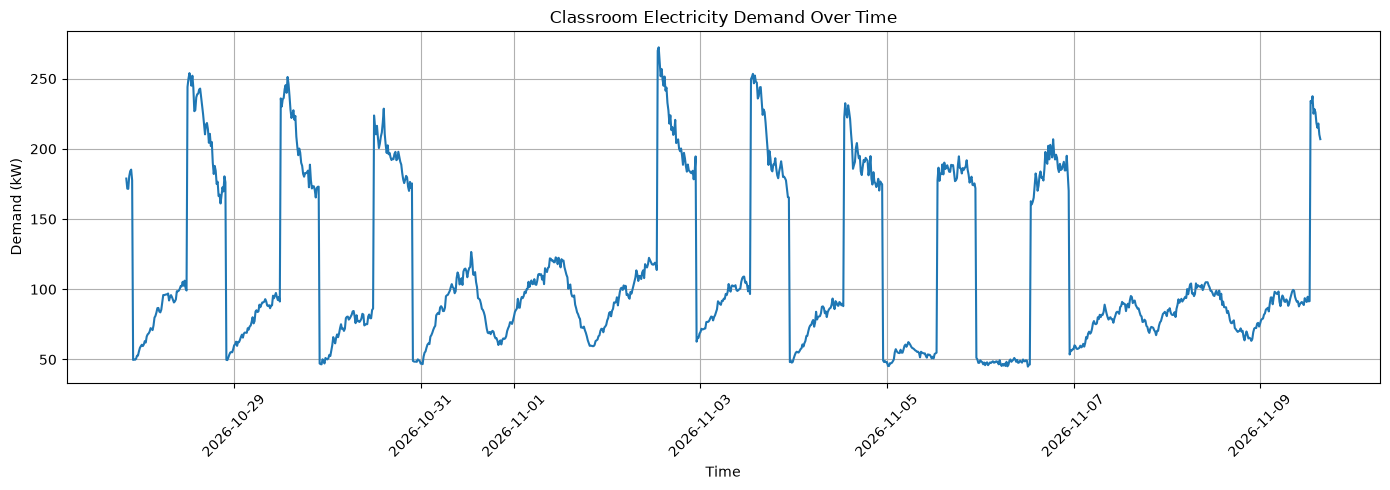

In [131]:
classroom_data = data[data["building_id"] == "classroom"].copy()

plt.figure(figsize=(14,5))
plt.plot(classroom_data["timestamp_utc"], classroom_data["demand_kw"])

plt.title("Classroom Electricity Demand Over Time")
plt.xlabel("Time")
plt.ylabel("Demand (kW)")
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

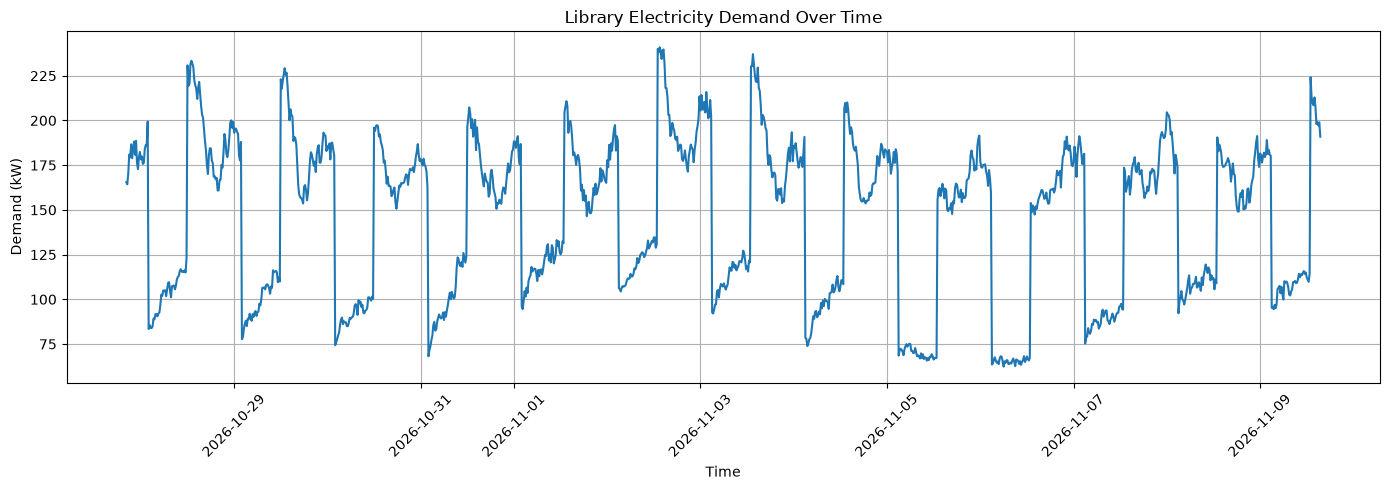

In [132]:
library_data = data[data["building_id"] == "library"].copy()

plt.figure(figsize=(14,5))
plt.plot(library_data["timestamp_utc"], library_data["demand_kw"])

plt.title("Library Electricity Demand Over Time")
plt.xlabel("Time")
plt.ylabel("Demand (kW)")
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

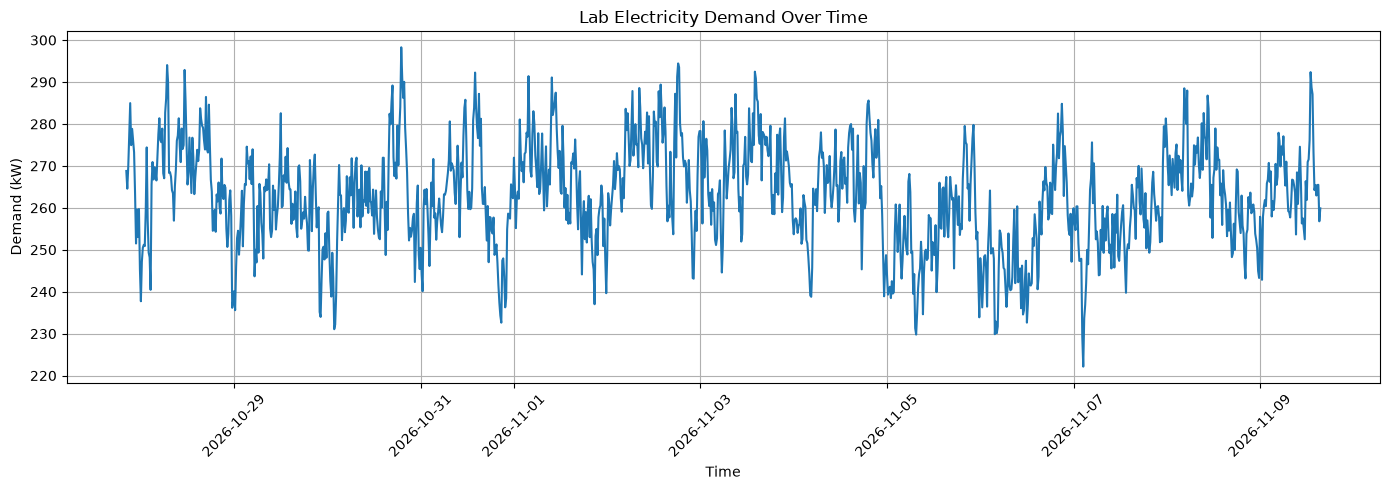

In [133]:
lab_data = data[data["building_id"] == "laboratory"].copy()

plt.figure(figsize=(14,5))
plt.plot(lab_data["timestamp_utc"], lab_data["demand_kw"])

plt.title("Lab Electricity Demand Over Time")
plt.xlabel("Time")
plt.ylabel("Demand (kW)")
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

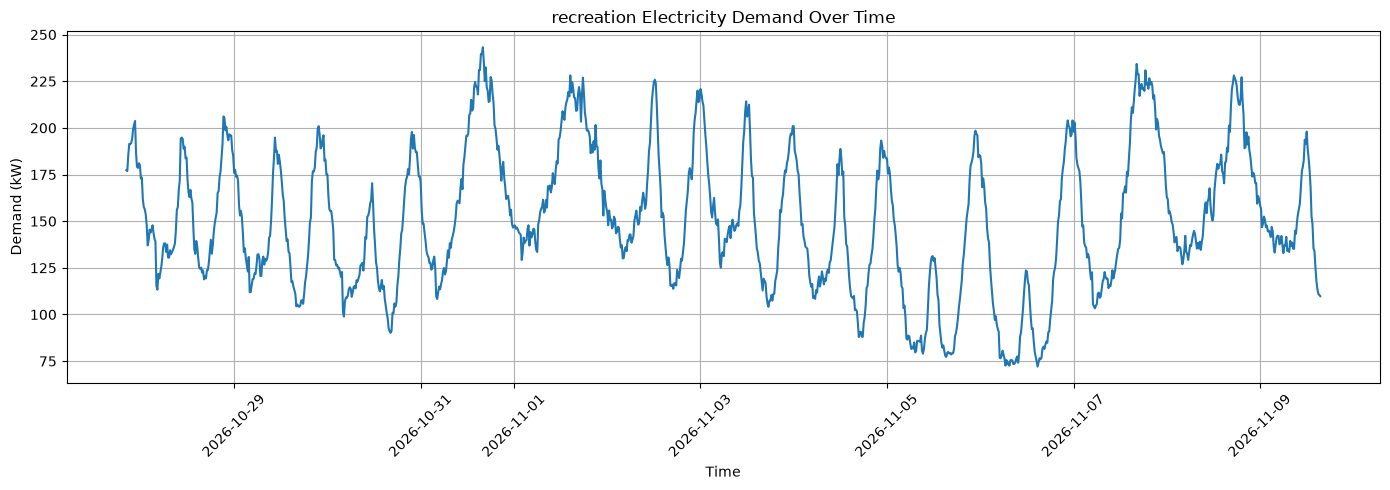

In [134]:
rec_data = data[data["building_id"] == "recreation"].copy()

plt.figure(figsize=(14,5))
plt.plot(rec_data["timestamp_utc"], rec_data["demand_kw"])

plt.title("recreation Electricity Demand Over Time")
plt.xlabel("Time")
plt.ylabel("Demand (kW)")
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

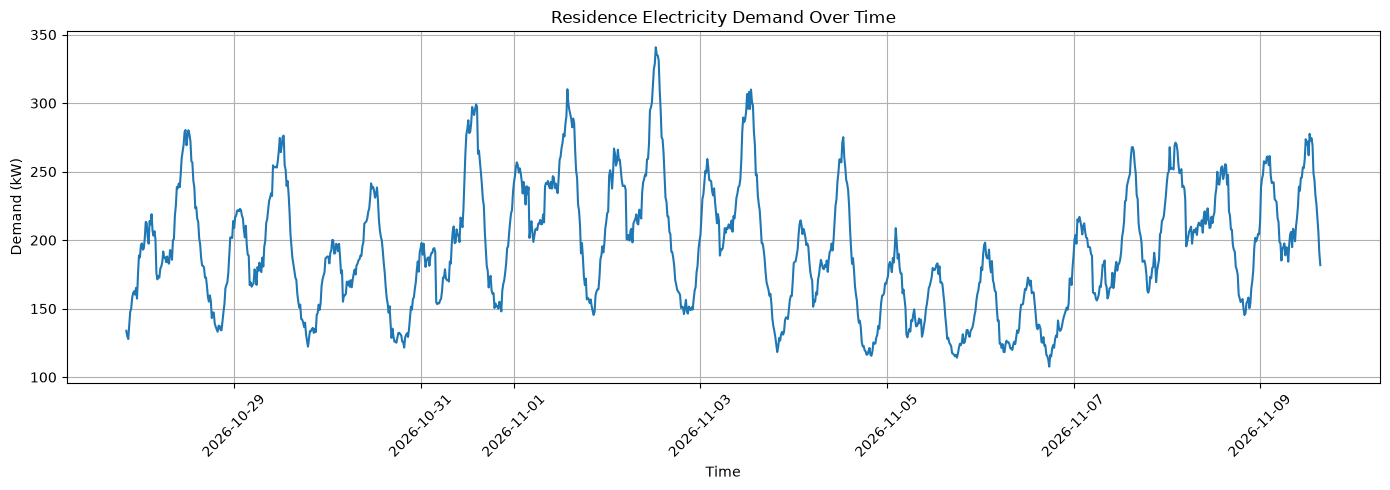

In [135]:
res_data = data[data["building_id"] == "residence"].copy()

plt.figure(figsize=(14,5))
plt.plot(res_data["timestamp_utc"], res_data["demand_kw"])

plt.title("Residence Electricity Demand Over Time")
plt.xlabel("Time")
plt.ylabel("Demand (kW)")
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()